In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sqlite3

In [2]:
conn = sqlite3.connect('customer_churn.db') # made a connection to the database using sqlite3.connect() method and stored it in a variable called conn.
sql_query = """  
select name 
from sqlite_master
where type='table';
"""                  # sql_query that contains a SQL query to retrieve the names of all tables in the database. The query selects the name column from the sqlite_master table, which is a system table that contains metadata about the database objects. The where clause filters the results to only include rows where the type is 'table', which means that only table names will be returned.
# sqlite uses this language
tables = pd.read_sql_query(sql_query, conn) # executed the SQL query and stored the results in a DataFrame called tables.
for table_name in tables['name']: 
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn)
    globals()[f"df_{table_name}"] = df # globals() function is used to create a variable with the name df_<table_name> and assign the DataFrame to it. The f-string is used to dynamically create the variable name based on the current table name.
    print(f"created a dataframe : df_{table_name}")


conn.close() # closed the connection to the database using the close() method of the connection object.

created a dataframe : df_db_customer
created a dataframe : df_db_subscription
created a dataframe : df_db_support


In [3]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [4]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     object
 1   name        21 non-null     object
 2   country     18 non-null     object
 3   state       21 non-null     object
 4   gender      21 non-null     object
 5   dob         21 non-null     object
 6   interests   4 non-null      object
 7   pincode     0 non-null      object
dtypes: object(8)
memory usage: 1.4+ KB


In [5]:
# a) rename column name 
# b) drop columns pincode , interests
# c) change datatype of dob
# d) gender standerzation 
# e) fix missing values in country
# f) name in proper format 


# a)
df_db_customer.rename(columns={'name': 'customer_name'}, inplace=True)

# b)
df_db_customer.drop(columns=['pincode', 'interests'], inplace=True  , errors='ignore')
# df_db_customer.drop(df_db_customer.columns[-2:], axis= 1)


# c)
df_db_customer['dob'] =  pd.to_datetime(df_db_customer['dob'])

# d)
df_db_customer['gender'] = df_db_customer['gender'].replace('Men', 'Male')
df_db_customer['gender'] = df_db_customer['gender'].replace('Women', 'Female')
# df_db_customer['gender'].replace({'Mens':'Male', 'Womens':'Female'})


# e) 
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

# f)
df_db_customer['customer_name'] =  df_db_customer['customer_name'].str.capitalize() # to convert the name to the proper case 

        

In [6]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,Keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,Raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,Lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,Mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,Mira,India,Delhi,Female,1990-05-05
5,0013-MHZWF,Durga,India,Delhi,Female,1988-12-10
6,0013-SMEOE,Mina,India,Meghalaya,Female,1976-09-21
7,0014-BMAQU,Madan,India,Rajasthan,Male,1999-03-14
8,0015-UOCOJ,Maya,Nepal,Kathmandu,Female,1985-07-07
9,0016-QLJIS,Arjun,Nepal,Kathmandu,Male,1993-10-29


In [7]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [8]:
date_cols = ['subscription_start_date' , 'renewal_date' , 'cancellation_date']
df_db_subscription[date_cols] = df_db_subscription[date_cols].apply(pd.to_datetime)

In [9]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     object        
 1   subscription_start_date  21 non-null     datetime64[ns]
 2   subscription_type        21 non-null     object        
 3   renewal_date             21 non-null     datetime64[ns]
 4   plan_type                21 non-null     object        
 5   contract_type            21 non-null     object        
 6   cancellation_date        6 non-null      datetime64[ns]
 7   cancellation_reason      6 non-null      object        
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 1.9+ KB


In [10]:
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])

In [11]:
df_db_support.drop(df_db_support.columns[-2:] , axis=1 , inplace=True)

In [12]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      object        
 1   complaint_date  9 non-null      datetime64[ns]
 2   escalations     9 non-null      object        
 3   csat_score      9 non-null      int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 420.0+ bytes


In [13]:
# feature engineering and data analysis

In [67]:
# create a new column
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna() ,1 ,0)

In [84]:
df = df_db_subscription.merge(df_db_customer , on= 'customerid' , how='left').merge(df_db_support , on= 'customerid' , how= 'left')

In [85]:
df_db_support['customerid'].nunique()

7

In [86]:
df_db_support['customerid'].shape

(7,)

In [87]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid' , keep= 'last')

In [88]:
# DATA ANALYSIS
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [89]:
# 1) Churn Rate
churn_rate = df['churn_flag'].mean()*100
print(f"churn_rate :{round((churn_rate),2)}","%")

churn_rate :28.57 %


In [90]:
# 2) Retention Rate
retention_rate = 100 - df['churn_flag'].mean()*100
print('retention_rate = ' , round(retention_rate,2) , '%')

retention_rate =  71.43 %


In [91]:
# 3) churn by plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean() * 100).round(2).reset_index(name='churn_rate_%')
print(churn_by_plan)

  plan_type  churn_rate_%
0     Basic         60.00
1   Premium         14.29
2  Standard         22.22


In [92]:
# 4.a) churn by state + sum(revenue) + count of users
churn_by_state = df.groupby('state').agg( total_revenue = ('cltv' , 'sum'), total_count = ('cltv' , 'count')).round(2).reset_index()
print(churn_by_state) # using aggregate function when we have to enter two values , reset index 

           state  total_revenue  total_count
0          Delhi           1765            4
1      Karnataka           1420            2
2      Kathmandu            575            2
3    Maharashtra           3027            3
4      Meghalaya            940            3
5       Nagaland           1725            1
6      Rajasthan           2680            2
7      Telangana           1022            2
8  Uttar Pradesh           4140            2


In [93]:
# 4.b) churn_by_subscription_type
churn_by_subscription_type = df.groupby('subscription_type').agg(total_revenue = ('cltv','sum'), count_users = ('subscription_type' , 'count')).reset_index()
print(churn_by_subscription_type)


  subscription_type  total_revenue  count_users
0           Organic           8360            9
1              Paid           7410            6
2          Refferal           1524            6


In [94]:
# 5) ARPU - Average Revenue Per User
ARPU = df['monthly_charges'].mean().round(2)
print(f"ARPU = {ARPU}")

ARPU = 18.85


In [95]:
# 6) Average Customer tenuere
today = pd.Timestamp.today()
df['tenuere_days'] =  np.where(
               df['cancellation_date'].notna(),
              (df['cancellation_date'] - df['subscription_start_date']).dt.days,
              (today - df['subscription_start_date']).dt.days     
)
average_tenuere = df['tenuere_days'].mean().round(2)
print('average_tenuere = ',average_tenuere , 'days')

average_tenuere =  1559.43 days


In [96]:
# 7) Revenue at risk - Revenue lost from churned user
revenue_at_risk = df.loc[df['churn_flag'] == 1 , 'monthly_charges'].sum()
print('revenue_at_risk = ',revenue_at_risk , 'k')
# Another way
# revenue_at_risks = (df['monthly_charges'] * df['churn_flag']).sum()
# print(f"Monthly revenue at risk: {revenue_at_risks}")

revenue_at_risk =  73.94 k


In [100]:
# 8) Esclation Rate 
esclation_rate = (df['escalations']=='Y').mean()*100
print("esclation_rate = " , round(esclation_rate,2) , '%')

esclation_rate =  19.05 %


In [110]:
# 9) average compalin per user
averege_complaint = (df['complaint_count'].sum() / df['customerid'].count()).round(2)
print("averege_complaint = ", averege_complaint , "complaint/user")

averege_complaint =  0.33 complaint/user


In [131]:
# 10) correlation between escalation and churn is 
# df['escalations'] =np.where(df['escalations'] == 'Y' , 1 , 0)  # encoding str to int
corr_df = df[['escalations' , 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn_flag'])
print("correlation between escalation and churn is = ",round(correlation,2))



correlation between escalation and churn is =  0.77


In [134]:
# 11) churn risk
conditions = [
    (df['churn_score'] < 50),
    (df['churn_score'] >= 50) & (df['churn_score'] < 70 ),
    (df['churn_score'] >= 70)
]
choises = ['low','medium','high']
df['churn_risk'] = np.select(conditions,choises,default='unknown')

In [ ]:
# Data visualization using matplotlib

In [136]:
df_visual = df.copy() # a copy of df for the visualization 

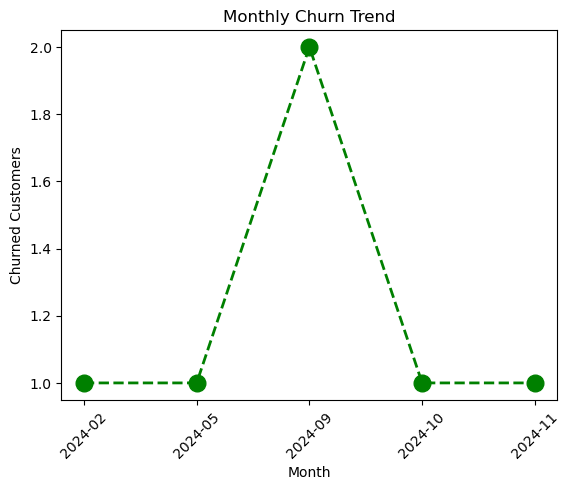

In [149]:
# 1) Monthly churn trend
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')
churn_trend = df_visual[df_visual['churn_flag'] ==1].groupby ('cancellation_month').size() 
plt.plot(
    churn_trend.index.astype(str),
    churn_trend.values,
    color='green',
    marker='o',
    linestyle='dashed',
    linewidth=2,
    markersize=12
)
plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.xticks(rotation=45)
plt.show()


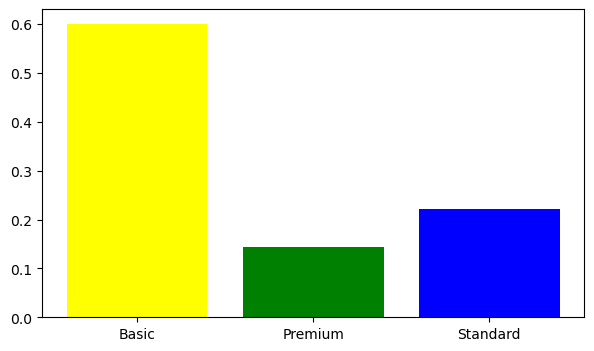

In [155]:
# 2) Churn By plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()
col = ['yellow' , 'green' , 'blue']
plt.figure(figsize=(7,4))
plt.bar(churn_plan.index,churn_plan.values , color= col)

plt.show()

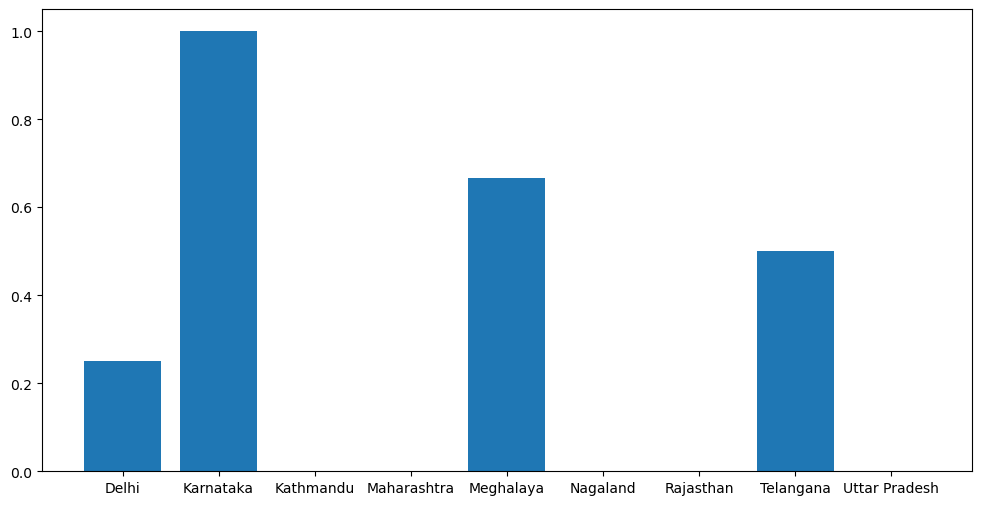

In [163]:
# 
churn_state = df_visual.groupby('state')['churn_flag'].mean()

plt.figure(figsize=(12,6))
plt.bar(churn_state.index,churn_state.values )
plt.show()

In [ ]:
# Data visualization using seaborn

In [168]:
# incorrect method of encoding as there are not encoded on the basis of priority

df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score' , 'churn_flag', 'churn_risk' , 'escalations']]
categorial_cols = ['plan_type' , 'contract_type', 'churn_risk']

for i in categorial_cols:
    df_encoded[i] = df_encoded[i].astype('category').cat.codes

C:\Users\garvi\AppData\Local\Temp\ipykernel_13592\1859110924.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_encoded[i] = df_encoded[i].astype('category').cat.codes
C:\Users\garvi\AppData\Local\Temp\ipykernel_13592\1859110924.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_encoded[i] = df_encoded[i].astype('category').cat.codes
C:\Users\garvi\AppData\Local\Temp\ipykernel_13592\1859110924.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using

<Axes: >

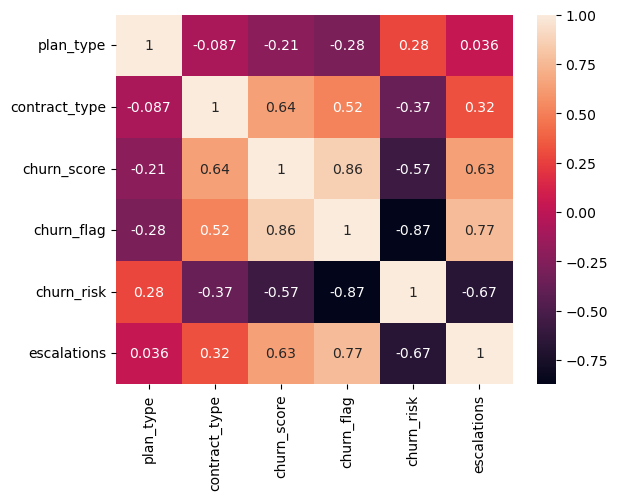

In [170]:
sns.heatmap(df_encoded.corr(), annot=True)

In [175]:
# correct method of encoding as they are orgainse on the basis of priority


df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score' , 'churn_flag', 'churn_risk' , 'escalations']]
order_mapping = {'plan_type' :['Basic','Standard','Premium'],
                 'contract_type' : ['Monthly' , 'Annual'], 
                 'churn_risk' :['low','medium','high']}

for i,order in order_mapping.items():
    df_encoded[i] =pd.Categorical( df_encoded[i].astype('category') , categories=order , ordered=True).codes


C:\Users\garvi\AppData\Local\Temp\ipykernel_13592\2865767577.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_encoded[i] =pd.Categorical( df_encoded[i].astype('category') , categories=order , ordered=True).codes
C:\Users\garvi\AppData\Local\Temp\ipykernel_13592\2865767577.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_encoded[i] =pd.Categorical( df_encoded[i].astype('category') , categories=order , ordered=True).codes
C:\Users\garvi\AppData\Local\Temp\ipykernel_13592\2865767577.py:10: Settin

<Axes: >

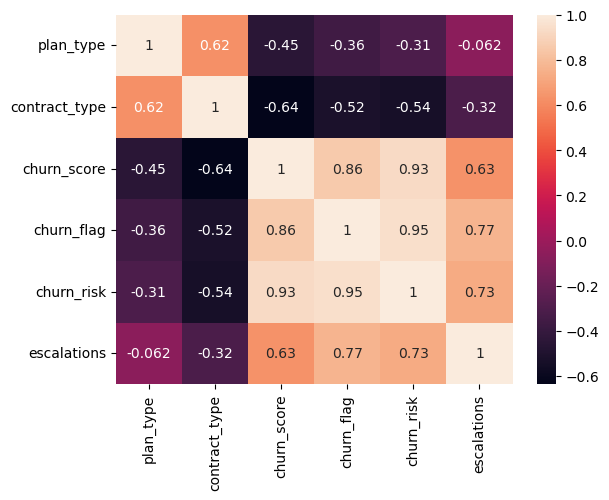

In [176]:
sns.heatmap(df_encoded.corr(), annot=True)

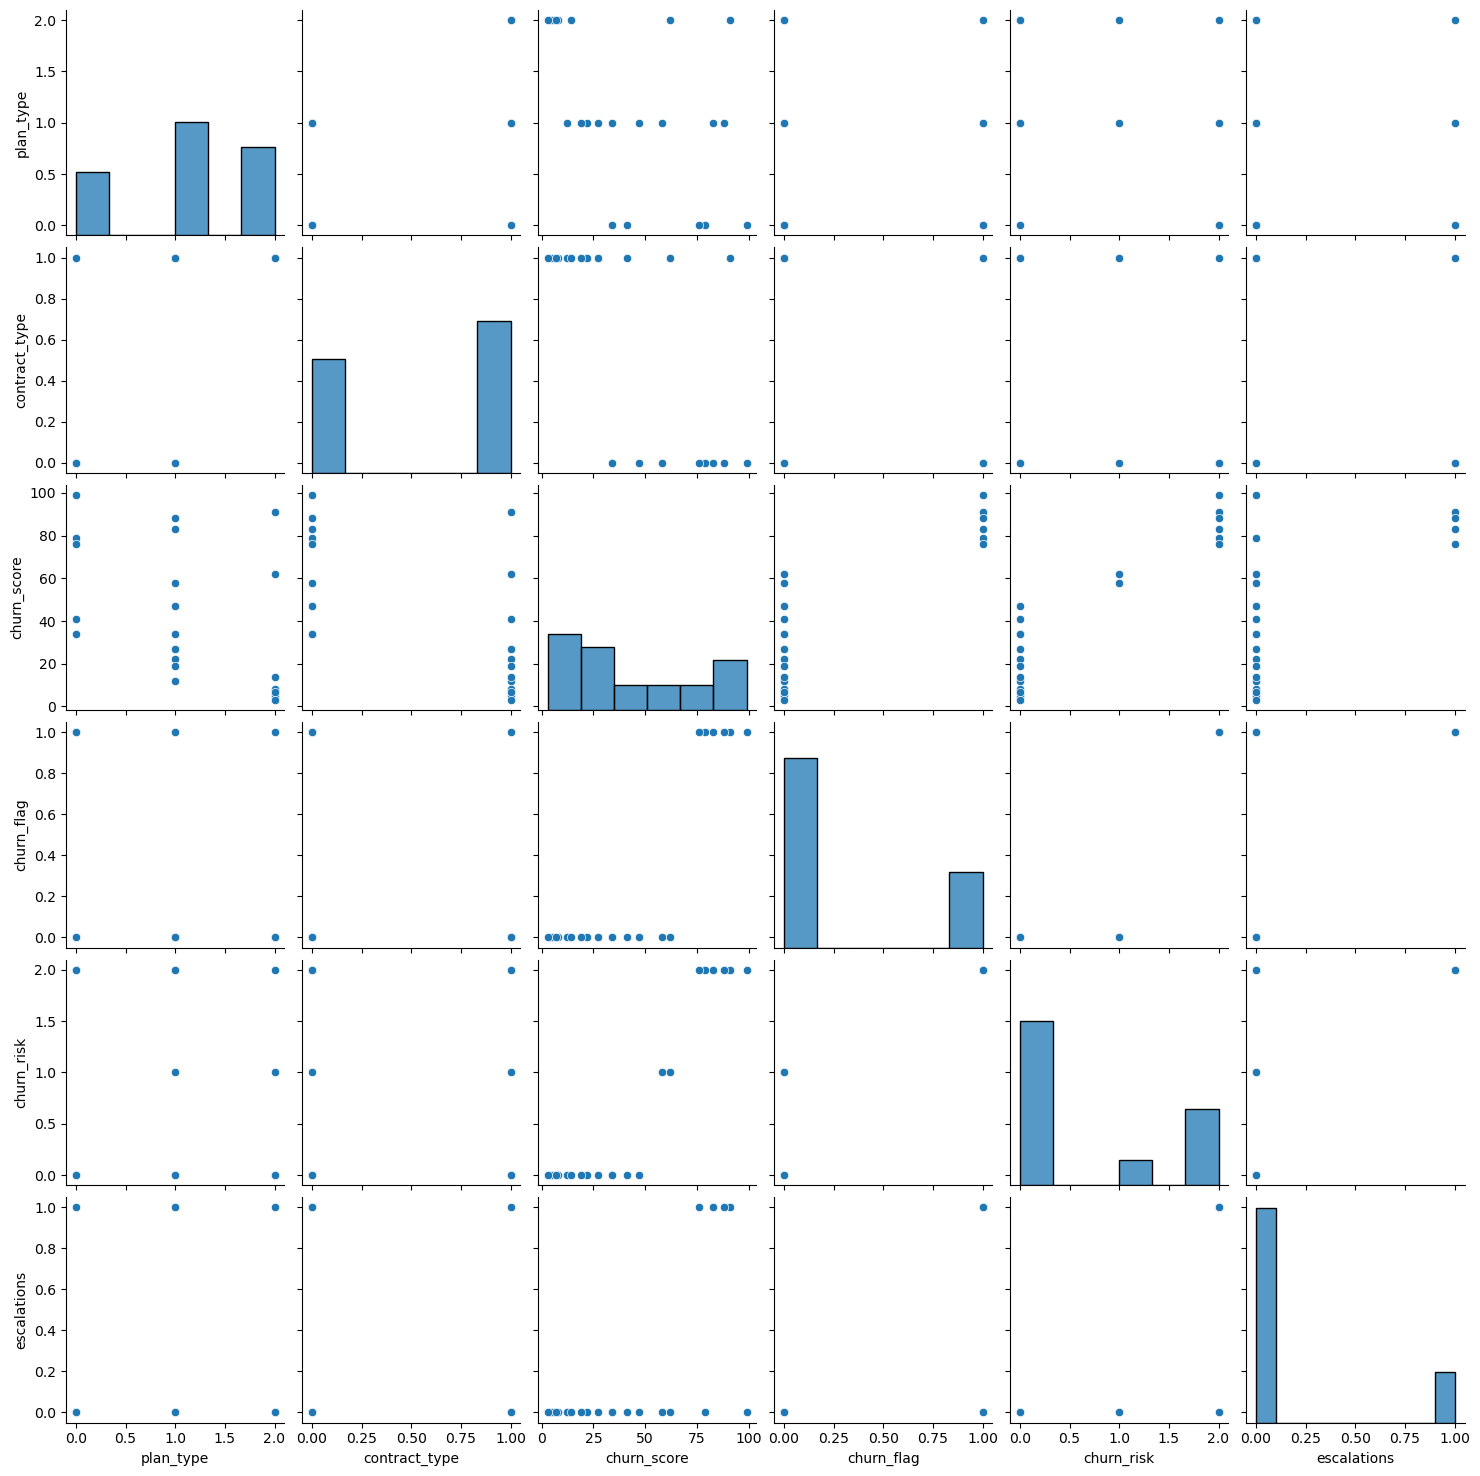

In [177]:
sns.pairplot(df_encoded)

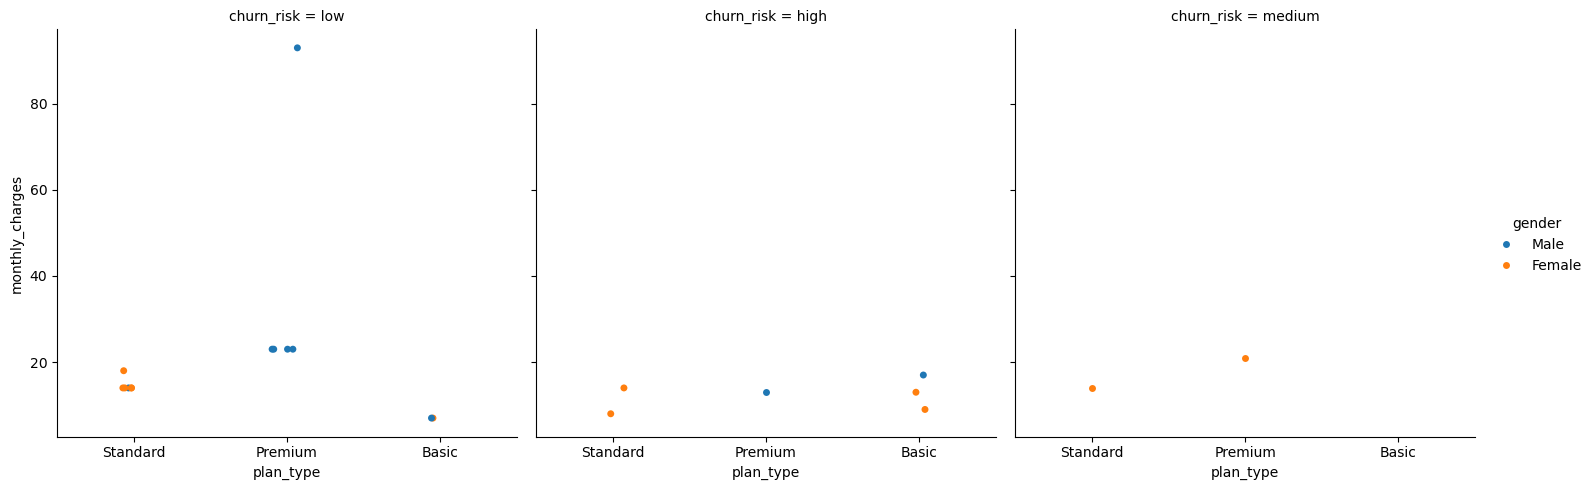

In [178]:
sns.catplot(data = df_visual , x='plan_type' , y='monthly_charges' , hue='gender' , col='churn_risk')

In [ ]:
# Pivote Tables

In [180]:
pd.pivot_table(
    df_visual ,
    index='plan_type',
    values='churn_flag',
    aggfunc='mean'
).reset_index()

,plan_type,churn_flag
0,Basic,0.600000
1,Premium,0.142857
2,Standard,0.222222


In [183]:
pd.pivot_table(
    df_visual ,
    index='plan_type',
    values=['churn_flag','customerid','monthly_charges'],
    aggfunc={
        'churn_flag':'mean','customerid':'count','monthly_charges':'sum'
    }
).reset_index().round(2)

,plan_type,churn_flag,customerid,monthly_charges
0,Basic,0.60,5,52.95
1,Premium,0.14,7,218.93
2,Standard,0.22,9,123.91
